# Capítulo 5 · Actividad: ¿este tumor es benigno?

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/riosinda/ml-course/blob/main/notebooks/exercises/chapter_05/03_actividad_breast_cancer_logistica.ipynb)

Entrena una **regresión logística** que diga si un tumor de mama es **benigno o maligno**. Haz el mismo proceso que en las actividades del Titanic y de los autos: primero entiende los datos y después elige el modelo. El preprocesamiento lo decides tú.

Cada fila es una muestra. De la imagen del núcleo celular se miden 10 cosas (radio, textura, perímetro, área, suavidad, compacidad, concavidad, puntos cóncavos, simetría y dimensión fractal). Cada una aparece tres veces:

| Grupo de columnas | Qué es |
|---|---|
| `mean ...` | Media de esa medida en la muestra |
| `... error` | Error estándar |
| `worst ...` | Media de los tres valores más grandes |
| `target` | **Target**: `0` = maligno, `1` = benigno |

`target` sale al revés de lo que uno esperaría: **1 es el caso benigno**.

Como mínimo, tu notebook debe incluir:

- La exploración de antes de modelar: forma de la tabla, balance de las dos clases, distribuciones, correlaciones y qué variables separan maligno de benigno.
- Una **regresión logística**. Las columnas no están en la misma escala (el área va por cientos y la suavidad por centésimas): decide si estandarizas.
- Métricas de **clasificación** con validación cruzada y en prueba. Como mínimo: accuracy, matriz de confusión y AUC. La accuracy sola engaña: hay más benignos que malignos.
- Tus **conclusiones**: qué modelo te quedas y por qué. Decir que un tumor maligno es benigno no es el mismo error al revés.

1. **Copia esta notebook a `workspace/`** y trabaja sobre la copia.
2. Si todavía no tienes los datos: `uv run python scripts/download_data.py`


In [10]:
from pathlib import Path

import pandas as pd

raiz = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
df = pd.read_csv(raiz / "data" / "breast_cancer.csv")
df.head()


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


## Balance de Clases

target
1    357
0    212
Name: count, dtype: int64


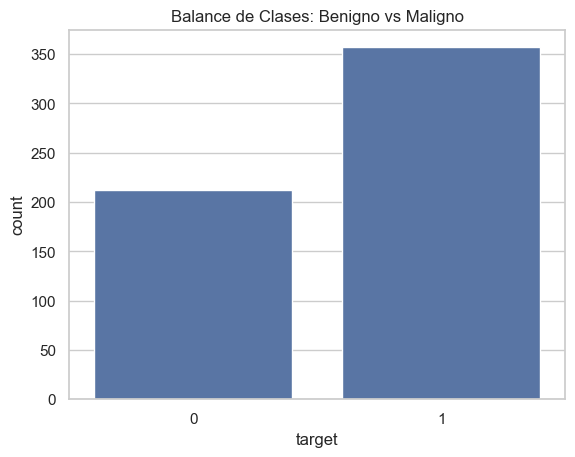

In [11]:
# Conteo numérico exacto de cada clase
print(df['target'].value_counts())

# Gráfico de barras para el balance
sns.countplot(x='target', data=df)
plt.title('Balance de Clases: Benigno vs Maligno')
plt.show()

## Distribución y escalas

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,0.627417
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,1.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,1.000000


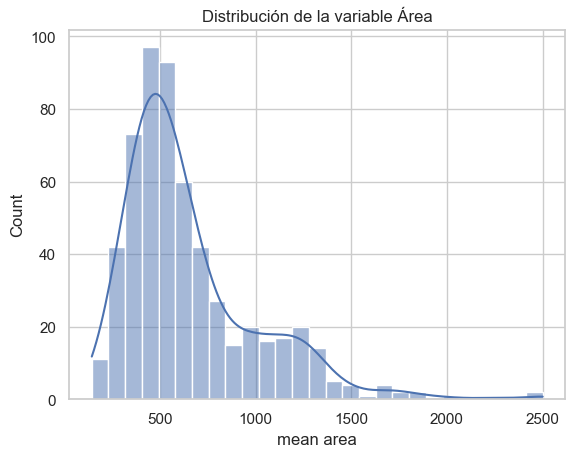

In [12]:
# Resumen estadístico (medias, máximos, mínimos) para ver la diferencia de escalas
display(df.describe())

# Histograma para ver la forma de la distribución de una variable específica
sns.histplot(df['mean area'], kde=True)
plt.title('Distribución de la variable Área')
plt.show()

## Correlaciones

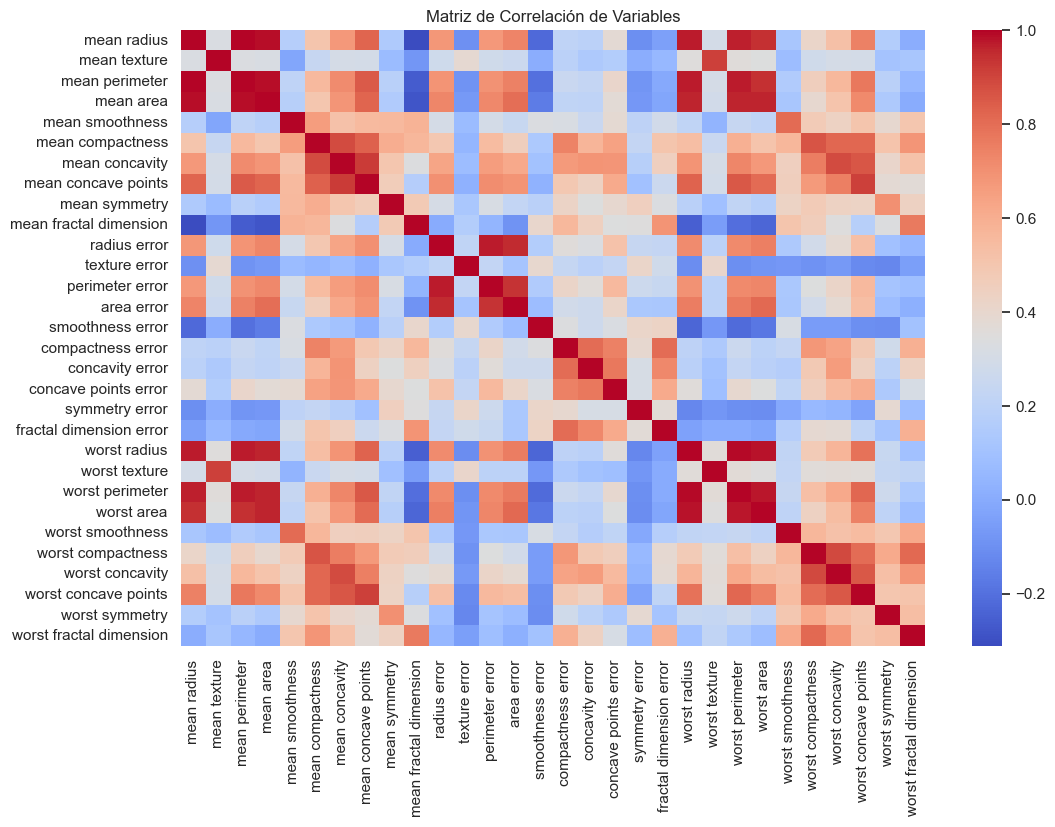

In [13]:
# Calcular la matriz de correlación (excluyendo la columna objetivo si es texto)
matriz_corr = df.drop(columns=['target']).corr()

# Visualizar la matriz térmica
plt.figure(figsize=(12, 8))
sns.heatmap(matriz_corr, cmap='coolwarm', annot=False) 
plt.title('Matriz de Correlación de Variables')
plt.show()

## Variables que separan un maligno de un benigno

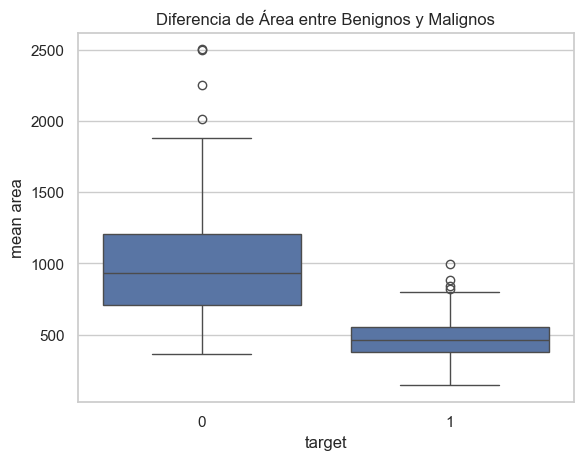

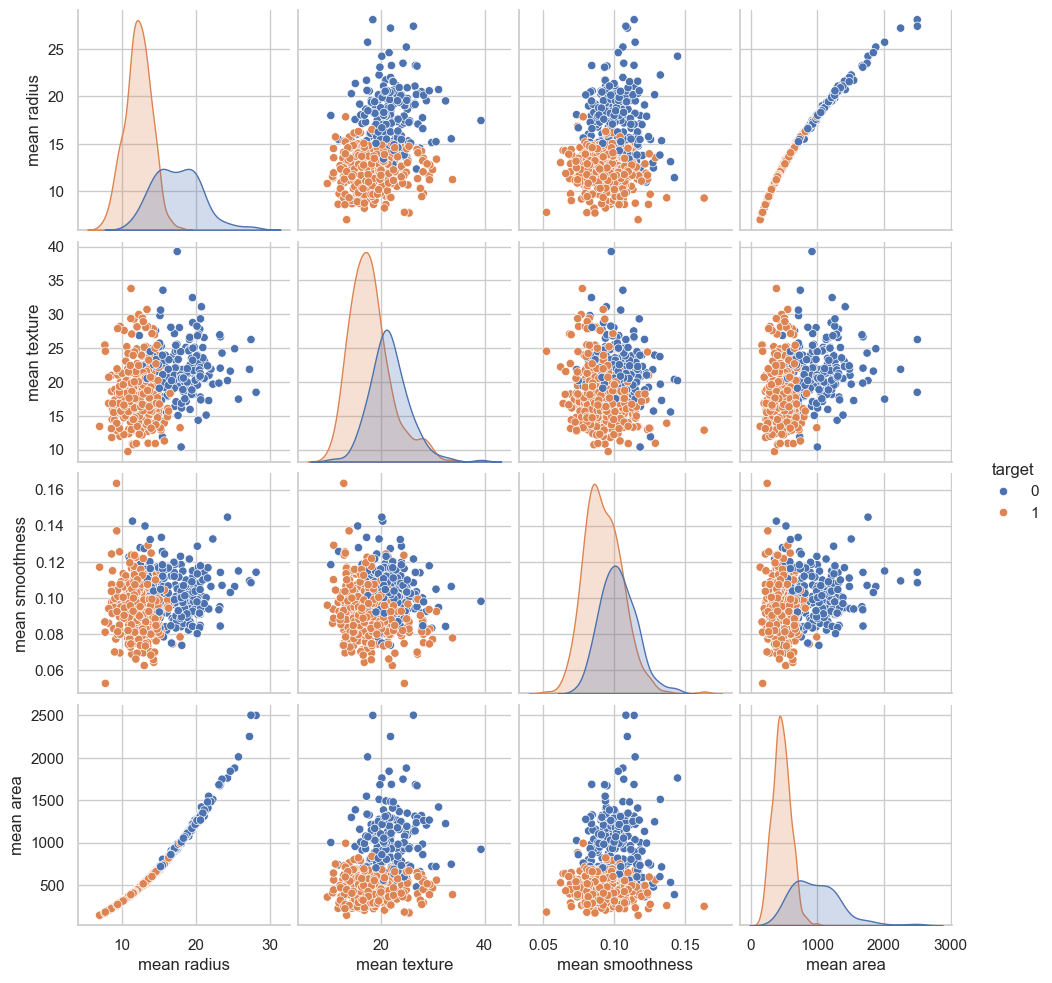

In [16]:
# Opción A: Boxplot para ver cómo se distribuye una variable según la clase
sns.boxplot(x='target', y='mean area', data=df)
plt.title('Diferencia de Área entre Benignos y Malignos')
plt.show()

# Opción B: Pairplot para ver relaciones entre múltiples variables al mismo tiempo
# (Filtra solo 4 o 5 columnas importantes para que la celda no tarde mucho en procesar)
columnas_interes = ['mean radius', 'mean texture', 'mean smoothness', 'mean area', 'target']
sns.pairplot(df[columnas_interes], hue='target')
plt.show()